<a href="https://colab.research.google.com/github/FOFM030711/SIMULACION-II/blob/main/Modelo%20SIR%20con%20pyMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <span style="color:purple;">**Modelo SIR con PyMC**</span>
<span style="color:purple;"></span>

<span style="color:leal;">**Nombre: Florencio Florencio Miriam Lizeth**</span>

 <span style="color:red;">**Objetivo:**</span>
El objetivo de este proyecto es analizar el comportamiento de un modelo SIR y estimar sus parámetros a partir de datos observados, utilizando diferentes métodos de ajuste y técnicas de inferencia estadística. En una primera etapa, se implementa la solución numérica del sistema de ecuaciones diferenciales para estudiar la evolución de las poblaciones de susceptibles, infectados y recuperados. Posteriormente, se emplea el método de mínimos cuadrados y la función estadística chi-cuadrada  para evaluar la diferencia entre los datos observados y los valores estimados por el modelo.

---
<span style="color:brown;">**NTRODUCCION**</span>



El estudio de los modelos matemáticos y la simulación computacional permite comprender el comportamiento de fenómenos que evolucionan a lo largo del tiempo, como la propagación de enfermedades infecciosas. En este contexto, el modelo SIR (Susceptibles, Infectados y Recuperados) constituye una herramienta matemática que permite representar la dinámica de una epidemia mediante un sistema de ecuaciones diferenciales. Este modelo divide a la población en tres grupos: individuos susceptibles de contraer la enfermedad, individuos infectados capaces de transmitirla e individuos recuperados que dejan de formar parte de la población infectada.


Además, se utiliza el método de Monte Carlo por cadenas de Markov (MCMC), específicamente el algoritmo Metropolis-Hastings, para explorar los valores posibles de los parámetros y encontrar aquellos que proporcionan un mejor ajuste a los datos. Finalmente, se incorpora PyMC como herramienta para desarrollar un enfoque bayesiano, mediante el cual se pueden estimar las distribuciones posteriores de los parámetros del modelo, considerando tanto la información proporcionada por los datos como el conocimiento previo que se tenga sobre ellos.

La incorporación de PyMC permite complementar el análisis tradicional de ajuste de parámetros, ya que no se limita a obtener un único conjunto de valores óptimos, sino que también permite estudiar la incertidumbre asociada a las estimaciones. De esta manera, es posible comparar los resultados obtenidos mediante mínimos cuadrados, Metropolis-Hastings y el enfoque bayesiano, identificando las ventajas y limitaciones de cada método para representar la evolución de la epidemia.

En conjunto, este proyecto busca demostrar cómo la simulación numérica, la optimización y la inferencia bayesiana pueden combinarse para analizar un fenómeno epidemiológico. Con ello, se pretende obtener una representación más completa del comportamiento del modelo SIR y comprender la importancia de estimar adecuadamente sus parámetros para interpretar la dinámica de propagación de una enfermedad.



---
---


##<span style="color:magenta;">**Modelo SIR**</span>


El modelo **SIR** consiste en tres Ecuacuiones Diferenciales Ordinarias No Lineales, no tiene una solucion analiticamente explicita. Es basicamente un modelo de enfermedades infecciosas.
Consiste en:
$$\frac{dS}{dt}=-aSI$$
$$\frac{dI}{dt}=aSI-bI$$
$$\frac{dR}{dt}=bI$$
donde
* $S=S(t)$ es susceptible
* $I(t)$ es infectado
* $R(t)$ es recuperado
* $a$ es la tasa de transmisión
* $b$ es la tasa de recuperación promedio

En cualquier momento, la población total es  $N = S + I + R$ y permanece constante como $N = S+ I+ R = 0$, donde el punto superior
indica la derivada con respecto al tiempo $t$.

Inicialmente, $S(t)$ es aproximadamente igual a $N$ e $I(t)$ es muy pequeño. En un brote, típicamente $I(t)$ aumenta cada día hasta alcanzar un máximo y luego tiende a disminuir lentamente.
Resulta particularmente útil determinar el número reproductivo, definido como $R_0 = \frac{a}{b}$ ya que el análisis del sistema dinámico indica que:
$$\frac{I_{max}}{N}=1-\frac{1}{R_0}(1+logR_0)$$

Por tanto, determinar los parámetros del modelo permite establecer el número máximo de infectados, una cifra que puede resultar útil para desarrollar medidas de salud pública. Incluso una vez ocurrido el evento, conocer los parámetros *a* y *b* del modelo es de interés, ya que sirven para caracterizar la enfermedad. Este es precisamente el problema que nos interesa resolver: determinar el par de parámetros $(a, b)$ del modelo $SIR$ a partir de un conjunto de datos.




---
En el articulo se plantea el análisis de un brote de gripe ocurrido en un internado, a partir de un conjunto de datos que describe la evolución de la enfermedad a lo largo del tiempo. Estos datos, citados originalmente en la literatura y reproducidos en la tabla siguiente, se utilizan como referencia para estudiar el comportamiento de la epidemia mediante el modelo SIR. Como antecedente, se consideran los resultados obtenidos por Murray, quien estimó los parámetros del modelo con los siguientes valores aproximados: $(a \approx 0.00218)$ y $(b \approx 0.4485)$. Estos valores servirán como referencia para analizar y estimar los parámetros mediante inferencia bayesiana utilizando PyMC.


<span style="color:green;">**Tabla de datos de Influenza en una escuela**</span>

$
\boxed{
\begin{array}{lc}
\text{t} & 0 &  1& 2 & 3 & 4 & 5 & 6 & 7 & 8 & 9 & 10 & 11 &  12 & 13 & 14   \\
\hline
\text{$I(t)$} & 1& 3& 6& 25& 73& 222&294 &258 &237 &191 & 125 &69 & 27 & 11& 4\\
\end{array}
}
$


---



---



Asi que con base a nuestra informacion proporcionada (obtenida del articulo **The inverse problem of a dynamical system solved
with genetic algorithms
To cite this article: Ricardo Medel Esquivel et al 2021 J. Phys.: Conf. Ser. 1723 012021**), prodamos a lo siguiente:

***Instalar las bibliotecas necesarias y llamar librerias de PyMC***

In [4]:

# Instalar las bibliotecas necesarias en Google Colab
%pip install -q pymc arviz scipy matplotlib


In [5]:

# Mostrar las gráficas directamente en Google Colab
%matplotlib inline

import arviz as az                        # análisis y gráficas de resultados bayesianos
import matplotlib.pyplot as plt           # gráficas
import numpy as np                        # arreglos numéricos
import pymc as pm                         # modelado probabilístico y muestreo MCMC (NUTS)
from pymc.ode import DifferentialEquation # permite usar una EDO dentro de un modelo de PyMC
from scipy.integrate import solve_ivp     # que permite resolver numéricamente ecuaciones diferenciales ordinarias (EDO) mediante métodos numéricos.
from scipy.integrate import odeint        # resuelve la EDO "a mano" (gráficas y verificación)
import time                               #Esta libreria nos dira el tiempo de ejecución del muestreo

az.style.use("arviz-darkgrid")            # estilo de las gráficas






Con los datos de la tabla de influenza en el internado, adaptamos el programa para que PyMC, utilizando los 15 valores observados entre los días $0$ y $14$. Tambien consideremos los valores de Murray, $(a\approx 0.00218)$ y $(b\approx 0.4485)$

In [6]:
#Datos del brote de influenza en el internado
N = 763  # población total (alumnos)
t_datos = np.arange(0, 15)# días 0, 1, ..., 14
I_datos = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])

# El día 0 (I = 1) es la condición inicial, que se conoce.
# Los datos que el modelo debe explicar son los de los días 1 a 14.
t_obs = t_datos[1:]
I_obs = I_datos[1:]


Planteemos el **Modelo SIR**
$$\frac{dS}{dt}=-aSI$$
$$\frac{dI}{dt}=aSI-bI$$
$$\frac{dR}{dt}=bI$$
donde
* $S=S(t)$ es susceptible
* $I(t)$ es infectado
* $R(t)$ es recuperado
* $a$ es la tasa de transmisión
* $b$ es la tasa de recuperación promedio

/tmp/ipykernel_82815/1060431216.py:147: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


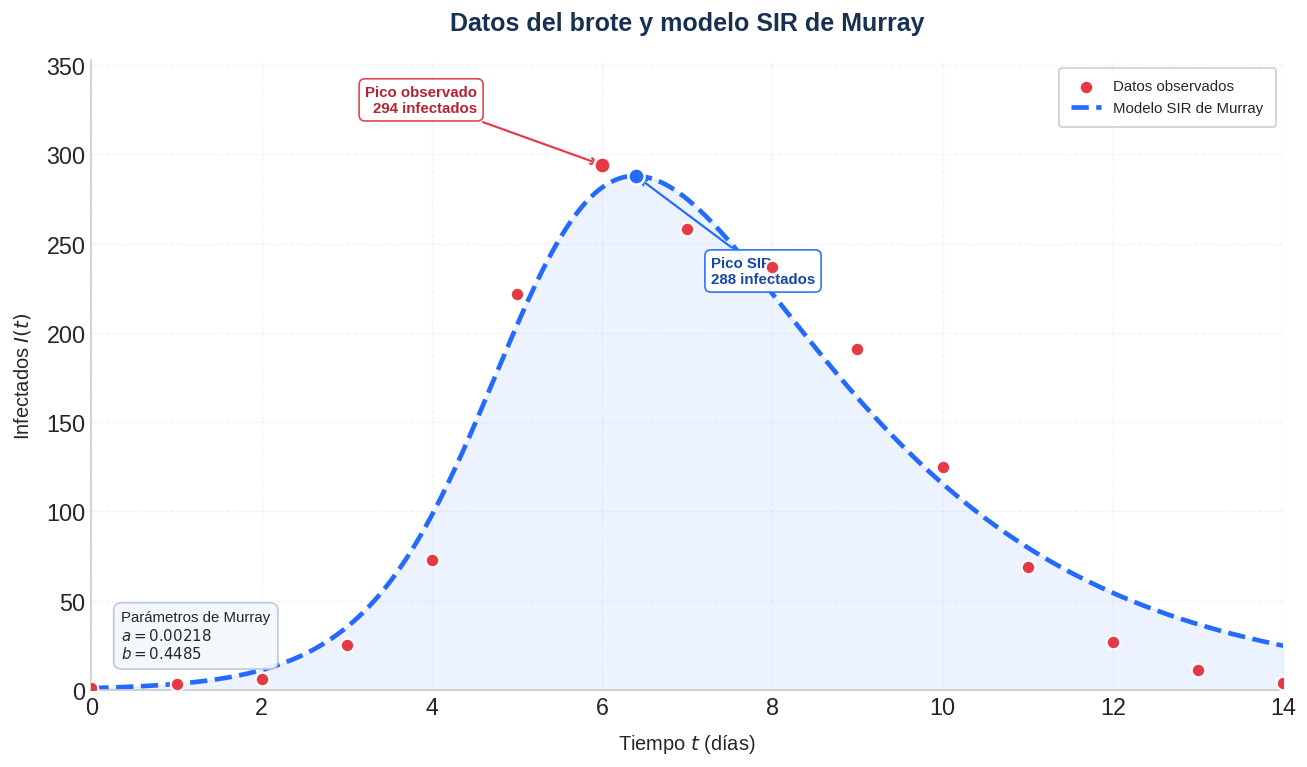

Pico del modelo SIR: 288 infectados en el día 6.40
Pico observado: 294 infectados en el día 6


In [7]:

# Figura 1: Gráfica SIR de Murray con diseño limpio

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# Definimos la función del modelo SIR para resolver la EDO
def modelo_sir(y, t, theta):
    S, I, R = y
    a, b = theta
    dS_dt = -a * S * I
    dI_dt = a * S * I - b * I
    dR_dt = b * I
    return [dS_dt, dI_dt, dR_dt]

# Parámetros de Murray
a_murray, b_murray = 0.00218, 0.4485
t_fino = np.linspace(0, 14, 500)
y0 = [N - 1, 1, 0]

# Resolver el modelo
curva_murray = odeint(
    modelo_sir, y0, t_fino,
    args=((a_murray, b_murray),),
    rtol=1e-8, atol=1e-10
)

I_murray = curva_murray[:, 1]

# Calcular picos
i_murray = np.argmax(I_murray)
t_pico = t_fino[i_murray]
I_pico = I_murray[i_murray]

i_datos = np.argmax(I_datos)
t_pico_datos = t_datos[i_datos]
I_pico_datos = I_datos[i_datos]

# Estilo general
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(11, 6.5), dpi=120)

# Datos observados
ax.scatter(
    t_datos, I_datos,
    s=65, color="#E63946",
    edgecolor="white", linewidth=1.2,
    zorder=5, label="Datos observados"
)

# Curva SIR
ax.plot(
    t_fino, I_murray,
    color="#246BFD", linewidth=2.8,
    linestyle="--", label="Modelo SIR de Murray"
)

ax.fill_between(
    t_fino, I_murray,
    color="#246BFD", alpha=0.08
)

# Pico observado: etiqueta arriba y a la izquierda
ax.scatter(t_pico_datos, I_pico_datos,
           color="#E63946", s=95, zorder=6,
           edgecolor="white", linewidth=1.5)

ax.annotate(
    f"Pico observado\n{I_pico_datos:.0f} infectados",
    xy=(t_pico_datos, I_pico_datos),
    xytext=(-75, 30),
    textcoords="offset points",
    ha="right", va="bottom",
    fontsize=9, color="#B42332",
    fontweight="bold",
    arrowprops=dict(arrowstyle="->",
                    color="#E63946", lw=1.3),
    bbox=dict(boxstyle="round,pad=0.4",
              fc="white", ec="#E63946", alpha=0.95)
)

# Pico del modelo: etiqueta abajo y a la derecha
ax.scatter(t_pico, I_pico,
           color="#246BFD", s=95, zorder=6,
           edgecolor="white", linewidth=1.5)

ax.annotate(
    f"Pico SIR\n{I_pico:.0f} infectados",
    xy=(t_pico, I_pico),
    xytext=(45, -48),
    textcoords="offset points",
    ha="left", va="top",
    fontsize=9, color="#1748A0",
    fontweight="bold",
    arrowprops=dict(arrowstyle="->",
                    color="#246BFD", lw=1.3),
    bbox=dict(boxstyle="round,pad=0.4",
              fc="white", ec="#246BFD", alpha=0.95)
)

# Título y etiquetas
ax.set_title(
    "Datos del brote y modelo SIR de Murray",
    fontsize=15, fontweight="bold",
    color="#183153", pad=18
)
ax.set_xlabel("Tiempo $t$ (días)", fontsize=12, labelpad=8)
ax.set_ylabel("Infectados $I(t)$", fontsize=12, labelpad=8)

# Espacio adicional para las anotaciones
ax.set_xlim(0, 14)
ax.set_ylim(0, max(max(I_datos), max(I_murray)) * 1.20)
ax.grid(True, linestyle="--", alpha=0.22)

# Ocultar bordes innecesarios
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Leyenda en la parte superior derecha
ax.legend(
    loc="upper right",
    fontsize=9,
    frameon=True,
    fancybox=True,
    framealpha=0.95,
    borderpad=0.8
)

# Parámetros en la parte inferior izquierda,
# separados de las anotaciones de los picos
ax.text(
    0.025, 0.045,
    f"Parámetros de Murray\n"
    f"$a = {a_murray}$\n"
    f"$b = {b_murray}$",
    transform=ax.transAxes,
    fontsize=9,
    va="bottom",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#F4F7FB",
        edgecolor="#B8C7DC",
        alpha=0.95
    )
)

plt.tight_layout()
plt.show()

# Resultados numéricos
print(f"Pico del modelo SIR: {I_pico:.0f} infectados "
      f"en el día {t_pico:.2f}")
print(f"Pico observado: {I_pico_datos:.0f} infectados "
      f"en el día {t_pico_datos}")


**Interpretación de la grafica**


* Podemos oservar que los puntos rojos representan los registros reales del numero de alumns internados infectados del dia $0$ al dia $14$. El pico real se alcanza en el día 6 con 294 infectados (marcado con una etiqueta roja).

* Mientras que la curva azul representa la curva terica del **Modelo SIR de Murray**, la cual es la solución numerica de las ecuaciones diferenciales del modelo SIR, usando $a = 0.00218$$a = 0.00218$ y la tasa de recuperación $b = 0.4485$$b = 0.4485$.
El pico de esta curva se alcanza en el día 6.40 con 288 infectados (marcado con una etiqueta azul).

 * La curva teórica se ajusta de forma asombrosa a los puntos reales. El modelo matemático de Murray logra capturar casi perfectamente tanto la velocidad de subida del contagio, el pico máximo de la epidemia (con una diferencia de solo 6 personas y menos de medio día de desfase) como la velocidad con la que disminuye la cantidad de enfermos.

### Transformación de la EDO en el entorno de PyMC y su relación con el teorema de Bayes

El modelo epidemiológico SIR se incorpora al entorno de PyMC mediante la función `DifferentialEquation`, que permite resolver numéricamente un sistema de ecuaciones diferenciales ordinarias (EDO) y utilizar sus soluciones dentro de un modelo probabilístico. En este caso, el sistema describe la evolución temporal de las poblaciones susceptibles, infectadas y recuperadas, representadas por las variables $(S(t))$, $(I(t))$ y $(R(t))$, respectivamente.

La relación entre el modelo SIR y el teorema de Bayes surge al considerar que los parámetros epidemiológicos, como la tasa de transmisión $(\beta)$ y la tasa de recuperación $(\gamma)$, son desconocidos y deben estimarse a partir de los datos observados. Para ello, se asignan distribuciones de probabilidad previas a dichos parámetros y se define una función de verosimilitud que permite evaluar qué tan compatibles son las predicciones del modelo con los datos epidemiológicos disponibles.

De acuerdo con el teorema de Bayes, la distribución posterior de los parámetros se expresa como:

$$
p(\theta\mid D)=
\frac{p(D\mid\theta)\,p(\theta)}{p(D)},
$$

donde $(\theta=(\beta,\gamma) )$ representa el conjunto de parámetros desconocidos y $(D )$ corresponde a los datos observados. En esta expresión:

- $(p(\theta\mid D) )$ es la **distribución posterior**, que representa el conocimiento actualizado de los parámetros después de considerar los datos.
- $(p(\theta) )$ es la **distribución previa**, que representa la información o los supuestos iniciales sobre los parámetros antes de observar los datos.
- $(p(D\mid\theta) )$ es la **función de verosimilitud**, que mide la compatibilidad de los datos observados con los valores propuestos para los parámetros.
- $p(D) )$ es la **evidencia marginal**, que normaliza la distribución posterior para que su integral sea igual a uno.

Cuando el objetivo es estimar los parámetros mediante inferencia bayesiana, también se utiliza la expresión proporcional:

**$$
p(\theta\mid D)\propto p(\theta)\,p(D\mid\theta).
$$**

Esta forma indica que la distribución posterior es proporcional al producto de la distribución previa y la verosimilitud.

En el modelo SIR, `DifferentialEquation` permite obtener las soluciones numéricas del sistema para los valores propuestos de \(\beta\) y \(\gamma\). Estas soluciones se utilizan para construir la verosimilitud, comparando las predicciones del modelo con los datos observados. Posteriormente, PyMC permite realizar la inferencia bayesiana y obtener las distribuciones posteriores de los parámetros.

Por lo tanto, la función `DifferentialEquation` establece el vínculo entre el sistema dinámico y el modelo probabilístico, mientras que el enfoque bayesiano permite estimar los parámetros epidemiológicos y cuantificar la incertidumbre asociada a ellos. De esta manera, el análisis no se limita a obtener una curva que describa la evolución de la enfermedad, sino que también permite evaluar la incertidumbre de las estimaciones y la variabilidad de los posibles escenarios epidemiológicos.

In [8]:

# Definimos explícitamente la función del sistema de ecuaciones diferenciales
def sir_ode_func(y, t, theta):
    S, I, R = y
    a = theta[0]
    b = theta[1]

    dS_dt = -a * S * I
    dI_dt = a * S * I - b * I
    dR_dt = b * I

    return [dS_dt, dI_dt, dR_dt]

# Objeto DifferentialEquation de PyMC
sir_model = DifferentialEquation(
    func=sir_ode_func,             # función explícita que define las EDO
    times=t_obs.astype(float),     # tiempos en los que se quiere la solución (sin t0)
    n_states=3,                    # número de variables de estado: S, I y R
    n_theta=2,                     # número de parámetros de la EDO: a y b
    t0=0,                          # tiempo inicial (donde se da y0)
)


La función recibe las poblaciones $(S)$, $(I )$ y $(R )$, el tiempo y los parámetros desconocidos $(a )$ y $(b )$. Devuelve las derivadas que **PyMC** utilizará para resolver numéricamente el sistema.

**Construccción del **Modelo Bayesiano en PyMC****





El modelo SIR bayesiano combina las ecuaciones diferenciales del modelo epidemiológico SIR con la inferencia bayesiana, con el propósito de estimar los parámetros epidemiológicos a partir de los datos observados, considerando explícitamente la incertidumbre asociada al proceso de observación.

**Etapa I. Modelo epidemiológico SIR**

El modelo SIR divide a la población en tres grupos: susceptibles, infectados y recuperados. Las ecuaciones diferenciales que describen la dinámica de la enfermedad son:

$$
\frac{dS}{dt}=-\beta\frac{SI}{N}
$$

$$
\frac{dI}{dt}=\beta\frac{SI}{N}-\gamma I
$$

\begin{equation}
\frac{dR}{dt}=\gamma I
\end{equation}

Donde:


* $S(t)$ representa el número de personas susceptibles de contraer la enfermedad.
* $I(t)$ representa el número de personas infectadas que pueden transmitirla.
* $R(t)$ representa el número de personas recuperadas o retiradas de la transmisión.
* $N$ representa el tamaño total de la población, supuesto constante.
* $\beta$ representa la tasa efectiva de transmisión.
* $\gamma$ representa la tasa de recuperación.


La población total satisface la relación:

\begin{equation}
N=S(t)+I(t)+R(t)
\end{equation}

Se utiliza el término $SI/N$ para normalizar el contacto infeccioso cuando las variables representan cantidades de personas. El sistema de ecuaciones diferenciales se resuelve numéricamente mediante la función **solve\_ivp** de la biblioteca **scipy.integrate** de Python.

**Etapa II. Distribuciones previas**

En el enfoque bayesiano, las distribuciones previas representan el conocimiento inicial acerca de los parámetros desconocidos antes de incorporar los datos observados.

Se define el vector de parámetros como:

\begin{equation}
\boldsymbol{\theta}=(\beta,\gamma,\sigma)
\end{equation}

donde $\sigma$ representa la escala del error de observación.

Para garantizar que los parámetros epidemiológicos sean positivos, se proponen las siguientes distribuciones previas:

\begin{equation}
\beta\sim\operatorname{LogNormal}(\mu_\beta,\tau_\beta)
\end{equation}

\begin{equation}
\gamma\sim\operatorname{LogNormal}(\mu_\gamma,\tau_\gamma)
\end{equation}

Para la escala del error de observación se utiliza una distribución normal truncada en cero:

\begin{equation}
\sigma\sim\operatorname{HalfNormal}(s_\sigma)
\end{equation}

Suponiendo independencia entre las distribuciones previas, la distribución conjunta de los parámetros es:

\begin{equation}
p(\beta,\gamma,\sigma)
=p(\beta)p(\gamma)p(\sigma)
\end{equation}

Los hiperparámetros $\mu_\beta$, $\tau_\beta$, $\mu_\gamma$, $\tau_\gamma$ y $s_\sigma$ deben seleccionarse considerando el conocimiento epidemiológico disponible y las unidades de tiempo utilizadas.

**Etapa III. Número reproductivo básico**

El número reproductivo básico, denotado por $R_0$, representa el número promedio de nuevas infecciones que genera una persona infectada durante su periodo infeccioso, cuando la población es completamente susceptible y bajo los supuestos del modelo.

Para el modelo SIR clásico se define como:

\begin{equation}
\boxed{R_0=\frac{\beta}{\gamma}}
\end{equation}

Esta expresión se obtiene considerando que $\beta$ representa la tasa efectiva de transmisión y que $1/\gamma$ es la duración infecciosa media.

Por otra parte, el número reproductivo efectivo en el tiempo $t$ se expresa como:

\begin{equation}
R_t=R_0\frac{S(t)}{N}
\end{equation}

La interpretación es la siguiente:

* Si $R_t>1$, la cantidad de infectados tiende a crecer en ese momento.
* Si $R_t<1$, la cantidad de infectados tiende a disminuir.
* Si $R_t=1$, la tasa instantánea de crecimiento de los infectados es cero en ese momento.


En el enfoque bayesiano, $R_0$ se calcula para cada muestra posterior de $\beta$ y $\gamma$. De esta manera, se obtiene una distribución posterior del número reproductivo básico que permite cuantificar su incertidumbre mediante intervalos creíbles.

**Etapa IV. Escala del error de observación**

Las soluciones del modelo SIR representan la evolución teórica de la epidemia, mientras que los datos reales pueden presentar discrepancias debido a errores de medición, subregistro y variabilidad epidemiológica.

Sea $y_i$ el número observado de infectados en el tiempo $t_i$, y sea $I(t_i;\beta,\gamma)$ la predicción del modelo. La relación entre los datos observados y las predicciones se representa mediante:

\begin{equation}
y_i=I(t_i;\beta,\gamma)+\varepsilon_i
\end{equation}

donde $\varepsilon_i$ representa el error de observación.

Para modelar esta incertidumbre se utiliza una distribución de Student:

\begin{equation}
y_i\sim t_\nu
\left(I(t_i;\beta,\gamma),\sigma\right)
\end{equation}

Donde:


* $I(t_i;\beta,\gamma)$ representa el centro de la distribución de observación.
* $\sigma$ representa la escala del error de observación.
* $\nu$ representa los grados de libertad de la distribución de Student.


La escala $\sigma$ controla la dispersión de las observaciones alrededor de las predicciones. Una escala pequeña indica que los datos se concentran más cerca de la curva del modelo, mientras que una escala grande permite discrepancias mayores.

Cuando $\nu>2$, la desviación estándar de la distribución de Student es:

\begin{equation}
\operatorname{DE}(y_i)=
\sigma\sqrt{\frac{\nu}{\nu-2}}
\end{equation}

Por lo tanto, la escala $\sigma$ no coincide necesariamente con la desviación estándar.

**Etapa V. Verosimilitud de Student**

La verosimilitud permite cuantificar la compatibilidad de los datos observados con las predicciones del modelo para determinados valores de los parámetros.

Definimos:

\begin{equation}
\mu_i=I(t_i;\beta,\gamma)
\end{equation}

La densidad de probabilidad de Student para cada observación es:

\begin{equation}
\begin{aligned}
p(y_i\mid\beta,\gamma,\sigma,\nu)
={}&
\frac{\Gamma\left(\frac{\nu+1}{2}\right)}
{\Gamma\left(\frac{\nu}{2}\right)
\sqrt{\nu\pi}\,\sigma}\\
&\times
\left[
1+\frac{1}{\nu}
\left(\frac{y_i-\mu_i}{\sigma}\right)^2
\right]^{-\frac{\nu+1}{2}}
\end{aligned}
\end{equation}

donde $\Gamma(\cdot)$ es la función gamma.

Suponiendo independencia condicional de las observaciones, la verosimilitud conjunta se expresa como:

\begin{equation}
L(\beta,\gamma,\sigma\mid\mathbf{y})
=
\prod_{i=1}^{n}
p(y_i\mid\beta,\gamma,\sigma,\nu)
\end{equation}

Para facilitar los cálculos numéricos, se utiliza el logaritmo de la verosimilitud:

\begin{equation}
\log L=
\sum_{i=1}^{n}
\log p(y_i\mid\beta,\gamma,\sigma,\nu)
\end{equation}

La distribución de Student presenta colas más pesadas que la distribución normal cuando sus grados de libertad son finitos. Por esta razón, permite reducir la influencia relativa de observaciones atípicas y resulta útil cuando los datos epidemiológicos presentan valores alejados de las predicciones.

Cuando $\nu$ aumenta, la distribución de Student se aproxima a la distribución normal.

**Etapa VI. Distribución posterior bayesiana**

El teorema de Bayes permite combinar la verosimilitud con las distribuciones previas para obtener la distribución posterior de los parámetros.

\begin{equation}
p(\beta,\gamma,\sigma\mid\mathbf{y})
\propto
L(\beta,\gamma,\sigma\mid\mathbf{y})
p(\beta)p(\gamma)p(\sigma)
\end{equation}

Esta expresión representa el conocimiento actualizado sobre los parámetros epidemiológicos después de incorporar los datos observados.

La distribución posterior contiene la información necesaria para estimar los parámetros y cuantificar la incertidumbre de las predicciones del modelo.

**Etapa VII. Muestreo MCMC**

El método de Monte Carlo basado en cadenas de Markov (MCMC) permite obtener muestras de la distribución posterior cuando su cálculo analítico resulta difícil.

En particular, el algoritmo de Metropolis-Hastings genera una secuencia de valores de los parámetros que, bajo las condiciones apropiadas, converge hacia la distribución posterior objetivo.

El procedimiento se desarrolla de la siguiente manera:


*  **Inicialización:** se seleccionan valores iniciales para $\beta$, $\gamma$ y $\sigma$, respetando sus restricciones.
    
* **Solución del modelo SIR:** para cada conjunto de parámetros propuesto, se resuelve el sistema de ecuaciones diferenciales mediante **solve\_ivp**.
    
* **Evaluación de la verosimilitud:** se comparan las predicciones del modelo con los datos observados utilizando la distribución de Student.
    
* **Propuesta de nuevos parámetros:** se genera un nuevo conjunto de valores mediante una distribución de propuesta.
    
* **Criterio de aceptación:** se calcula la probabilidad de aceptar la propuesta utilizando la razón entre las densidades posteriores.
    
* **Convergencia y resumen:** se descarta el periodo inicial o **burn-in**, se evalúa la convergencia de las cadenas y se resumen las muestras posteriores.


Sea $\boldsymbol{\theta}'$ el vector de parámetros propuesto y $\boldsymbol{\theta}$ el vector actual. La probabilidad de aceptación de Metropolis-Hastings es:

\begin{equation}
\alpha=
\min\left(
1,
\frac{
p(\boldsymbol{\theta}'\mid\mathbf{y})
q(\boldsymbol{\theta}\mid\boldsymbol{\theta}')
}{
p(\boldsymbol{\theta}\mid\mathbf{y})
q(\boldsymbol{\theta}'\mid\boldsymbol{\theta})
}
\right)
\end{equation}

donde $q(\boldsymbol{\theta}'\mid\boldsymbol{\theta})$ representa la distribución de propuesta.

Si la distribución de propuesta es simétrica, los términos correspondientes a $q$ se cancelan y la razón de aceptación depende de las densidades posteriores.

Una vez obtenidas las muestras, se calculan medidas resumen, como la mediana posterior, los intervalos creíbles y las distribuciones marginales de los parámetros.

**Etapa VIII. Interpretación de los resultados**

El procedimiento bayesiano permite obtener estimaciones de:


* La tasa de transmisión $\beta$.
* La tasa de recuperación $\gamma$.
*  La escala del error de observación $\sigma$.
* El número reproductivo básico $R_0=\beta/\gamma$.
* La evolución temporal de los infectados $I(t)$.


A diferencia de un ajuste determinista que proporciona una única curva, el enfoque bayesiano permite construir una distribución de curvas posibles y cuantificar la incertidumbre mediante intervalos creíbles.

En conclusión, el modelo SIR bayesiano integra las ecuaciones diferenciales epidemiológicas, las distribuciones previas, la verosimilitud de Student y el muestreo MCMC. La calidad de las estimaciones depende de los datos disponibles, de la elección de las distribuciones previas, de la formulación del error de observación y de la convergencia del algoritmo de muestreo.


In [9]:

# MODELO BAYESIANO


with pm.Model() as modelo_sir:

    # Distribuciones previas
    a = pm.LogNormal(
        "a",
        mu=np.log(0.00218),
        sigma=1.0
    )

    b = pm.LogNormal(
        "b",
        mu=np.log(0.4485),
        sigma=0.5
    )

    # Escala del error de observación
    sigma = pm.HalfNormal("sigma", sigma=30)

    # Número reproductivo básico:
    # S representa cantidades de personas
    R0 = pm.Deterministic("R0", a * N / b)

    # Resolver las ecuaciones diferenciales
    solucion = sir_model(
        y0=y0,
        theta=[a, b]
    )

    I_modelo = solucion[:, 1]

    # Verosimilitud de Student
    I_datos = pm.StudentT(
        "I_datos",
        nu=4,
        mu=I_modelo,
        sigma=sigma,
        observed=I_obs
    )

    # Muestreo MCMC
    idata = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        target_accept=0.95,
        random_seed=123,
        return_inferencedata=True
    )


Output()

En esta parte realiza:

* **Distribuciones previas**: establecen los valores plausibles iniciales de $(a)$ y $(b)$.
* **DifferentialEquation**: resuelve las ecuaciones SIR para cada conjunto de parámetros propuesto.
* **Verosimilitud de Poisson**: compara los infectados predichos con los observados.
* **pm.sample**: utiliza cadenas de Markov Monte Carlo para aproximar las distribuciones posteriores de los parámetros.

In [11]:

# RESUMEN DE LAS DISTRIBUCIONES POSTERIORES


resumen = az.summary(
    idata,
    var_names=["a", "b", "R0", "sigma"],
    hdi_prob=0.95,
    round_to=5
)

print("\nRESUMEN BAYESIANO")
print(resumen)


RESUMEN BAYESIANO
           mean       sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd    ess_bulk  \
a       0.00218  0.00004   0.00209    0.00227    0.00000  0.00000  2603.65238   
b       0.44645  0.01912   0.41052    0.48517    0.00037  0.00033  2726.19533   
R0      3.73575  0.15180   3.42346    4.02146    0.00270  0.00275  3244.08890   
sigma  19.15967  5.07745  10.65068   29.62388    0.10464  0.11564  2424.88717   

         ess_tail    r_hat  
a      2176.05401  1.00048  
b      2149.88027  1.00220  
R0     2215.52449  1.00168  
sigma  2451.95825  1.00278  




Para evaluar los parámetros del modelo SIR mediante el enfoque bayesiano, se obtuvo un resumen estadístico de las distribuciones posteriores utilizando la biblioteca ArviZ. Se analizaron los parámetros $(a )$, $(b )$, $(R_0 )$ y $(\sigma )$, considerando intervalos de máxima densidad posterior $(HDI) $ del $95 %$.

Incluye medidas como la media posterior, la desviación estándar, los intervalos de credibilidad y los indicadores de convergencia de las cadenas de muestreo. La media posterior proporciona una estimación central de cada parámetro, mientras que los intervalos HDI permiten evaluar la incertidumbre asociada a dichas estimaciones.

Asimismo, se revisa el estadístico $(\hat{R} )$ y el tamaño efectivo de muestra para comprobar si las simulaciones presentan una convergencia adecuada. Estos resultados permiten valorar la precisión de las estimaciones y analizar qué tan bien se han identificado los parámetros del modelo a partir de los datos observados.

/tmp/ipykernel_82815/3157440764.py:27: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


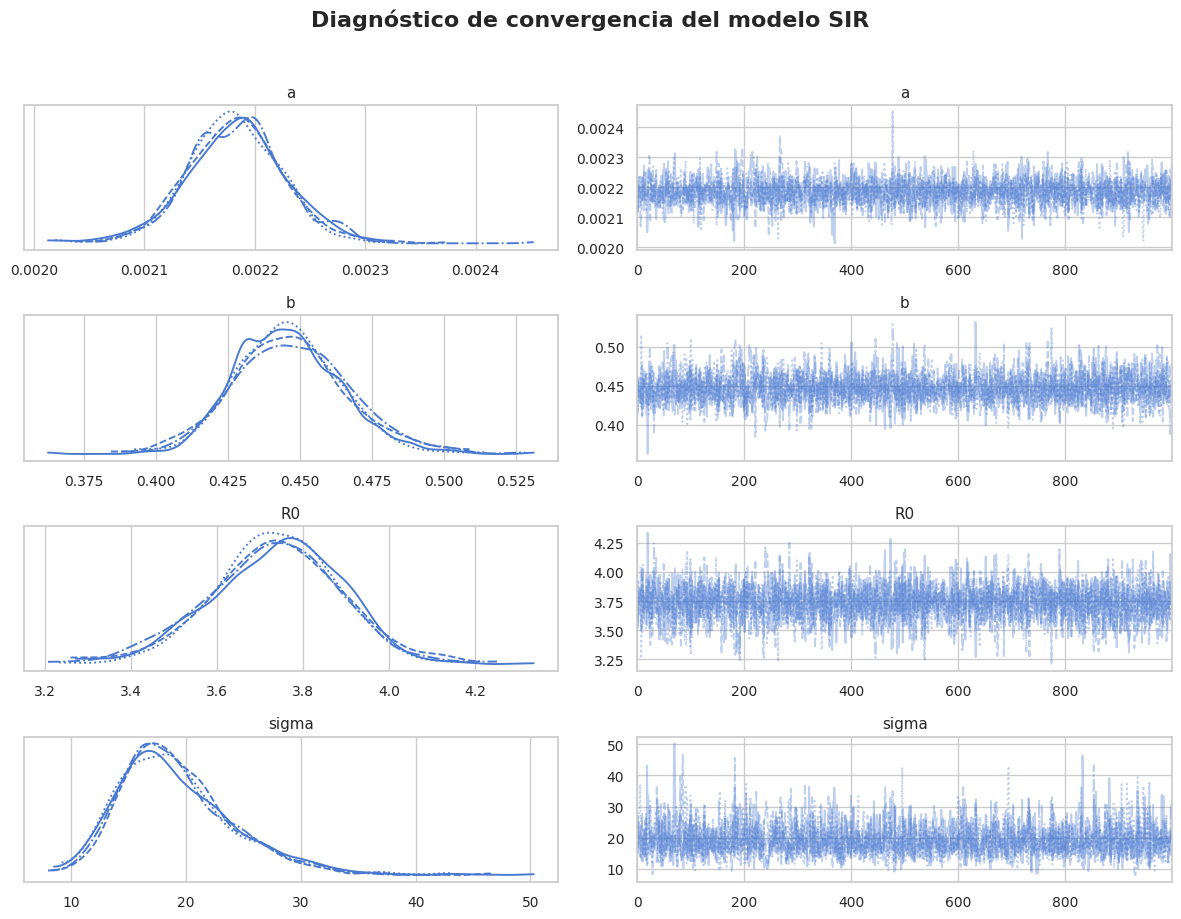


       RESUMEN DEL DIAGNÓSTICO BAYESIANO
          mean      sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd   ess_bulk   ess_tail   r_hat
a       0.0022  0.0000    0.0021     0.0023     0.0000   0.0000  2603.6524  2176.0540  1.0005
b       0.4465  0.0191    0.4105     0.4852     0.0004   0.0003  2726.1953  2149.8803  1.0022
R0      3.7358  0.1518    3.4235     4.0215     0.0027   0.0028  3244.0889  2215.5245  1.0017
sigma  19.1597  5.0774   10.6507    29.6239     0.1046   0.1156  2424.8872  2451.9582  1.0028

Número de divergencias: 0
✓ No se detectaron divergencias.


In [37]:

# DIAGNÓSTICO DE CONVERGENCIA DEL MODELO SIR


import arviz as az
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo de las gráficas
sns.set_theme(style="whitegrid", palette="muted")

# Gráficas de trazas
az.plot_trace(
    idata,
    var_names=["a", "b", "R0", "sigma"],
    compact=True,
    figsize=(12, 9),
    rug=False
)

plt.suptitle(
    "Diagnóstico de convergencia del modelo SIR",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

# Resumen estadístico
resumen = az.summary(
    idata,
    var_names=["a", "b", "R0", "sigma"],
    hdi_prob=0.95,
    round_to=4
)

print("\n" + "=" * 65)
print("       RESUMEN DEL DIAGNÓSTICO BAYESIANO")
print("=" * 65)
print(resumen.to_string())
print("=" * 65)

# Número de divergencias
divergencias = int(
    idata.sample_stats["diverging"].sum().values
)

print(f"\nNúmero de divergencias: {divergencias}")

if divergencias == 0:
    print("✓ No se detectaron divergencias.")
else:
    print("⚠ Se detectaron divergencias; revisa el ajuste del modelo.")

El diagnóstico de convergencia permite verificar si las simulaciones bayesianas del modelo SIR son confiables.
- Gráficas de trazas: muestran la estabilidad y el comportamiento de las cadenas de muestreo. Se espera que sean estables y se mezclen adecuadamente.
- Resumen de diagnósticos: se revisan indicadores como r_hat, que debe estar cerca de 1, y el tamaño efectivo de muestra.
- Divergencias: se cuentan los problemas detectados durante el muestreo. Lo ideal es obtener cero divergencias.
En conjunto, estos indicadores permiten evaluar si las estimaciones de los parámetros $(a )$, $(b )$, $(R_0 )$ y $(\sigma )$ presentan una convergencia adecuada.


**SIMULACIÓN DE TRAYECTORIAS POSTERIORES MODELO SIR BAYESIANO**


Procedamos a graficar las trayectorias del Modelo SIR para poder observar el ajuste bayesiano del modelo SIR, mostrando cómo evoluciona la población de infectados y la incertidumbre de las predicciones.


/tmp/ipykernel_82815/2255979070.py:79: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


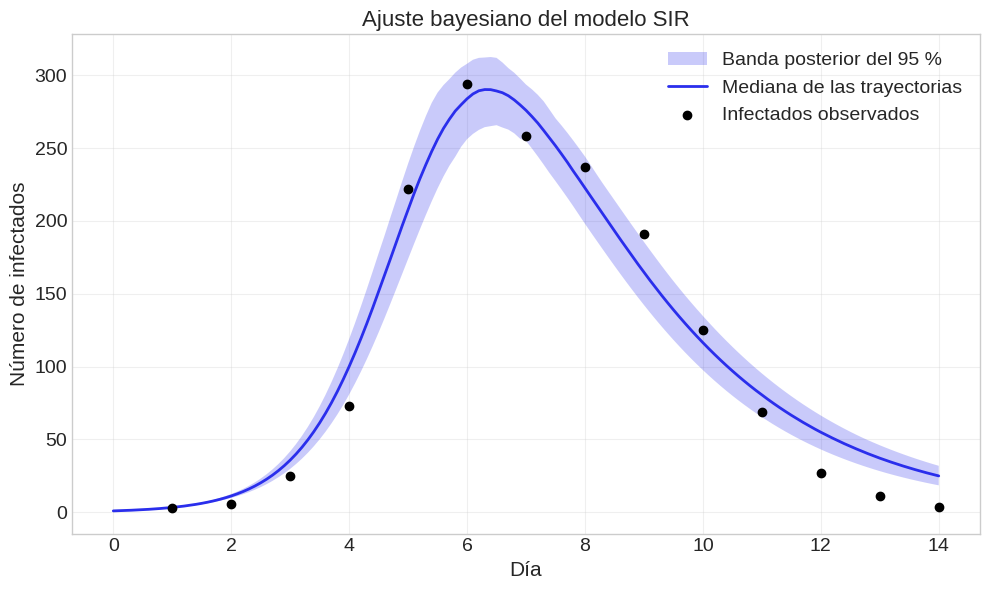

In [14]:


# Extraemos las muestras posteriores de los parámetros a y b.
# Estas muestras representan los posibles valores de los parámetros
# obtenidos mediante el ajuste bayesiano.
a_muestras = idata.posterior["a"].values.ravel()
b_muestras = idata.posterior["b"].values.ravel()

# Creamos una malla de tiempo de 0 a 14 días,
# con intervalos de 0.1 días para obtener curvas suaves.
t_fino = np.linspace(0, 14, 141)


# Definimos el sistema de ecuaciones diferenciales del modelo SIR.
# S: personas susceptibles.
# I: personas infectadas.
# R: personas recuperadas.
# a: tasa de transmisión.
# b: tasa de recuperación.
def sistema_sir(t, y, a, b):
    S, I, R = y

    return [
        -a * S * I,          # Cambio en la población susceptible.
        a * S * I - b * I,   # Cambio en la población infectada.
        b * I                # Cambio en la población recuperada.
    ]


# Fijamos una semilla para que la selección de muestras
# sea reproducible al ejecutar nuevamente el código.
rng = np.random.default_rng(123)

# Seleccionamos hasta 200 muestras posteriores para simular
# diferentes trayectorias posibles del número de infectados.
n_curvas = min(200, len(a_muestras))

indices = rng.choice(
    len(a_muestras),
    size=n_curvas,
    replace=False
)

# Creamos una lista vacía para almacenar las trayectorias
# de la población infectada obtenidas en cada simulación.
curvas = []

# Simulamos el modelo SIR utilizando los valores posteriores
# de los parámetros a y b seleccionados.
for j in indices:

    # Resolvemos numéricamente el sistema de ecuaciones
    # diferenciales para cada combinación de parámetros.
    sol = solve_ivp(
        lambda t, y: sistema_sir(
            t, y, a_muestras[j], b_muestras[j]
        ),
        (0, 14),             # Intervalo de simulación.
        y0,                   # Condiciones iniciales S, I y R.
        t_eval=t_fino,        # Instantes donde evaluamos la solución.
        rtol=1e-7,             # Tolerancia relativa del método.
        atol=1e-8              # Tolerancia absoluta del método.
    )

    # Si la solución se obtuvo correctamente, guardamos
    # únicamente la trayectoria de la población infectada.
    if sol.success:
        curvas.append(sol.y[1])

# Convertimos la lista en un arreglo para facilitar
# los cálculos estadísticos entre las trayectorias.
curvas = np.asarray(curvas)


# CÁLCULO DEL INTERVALO POSTERIOR DEL 95 %


# Calculamos los percentiles 2.5 y 97.5 en cada instante.
# Estos límites forman una banda que contiene el 95 %
# central de las trayectorias simuladas.
inferior = np.percentile(curvas, 2.5, axis=0)
superior = np.percentile(curvas, 97.5, axis=0)

# Calculamos la mediana de las trayectorias en cada instante.
# Esta curva representa la evolución central de las simulaciones.
mediana = np.median(curvas, axis=0)



# GRÁFICA DE LAS TRAYECTORIAS POSTERIORES


# Definimos el tamaño de la figura.
plt.figure(figsize=(10, 6))

# Dibujamos la banda posterior del 95 %.
# El área sombreada muestra la variabilidad entre trayectorias.
plt.fill_between(
    t_fino,
    inferior,
    superior,
    alpha=0.25,
    label="Banda posterior del 95 %"
)

# Graficamos la mediana de las trayectorias simuladas.
plt.plot(
    t_fino,
    mediana,
    linewidth=2.5,
    label="Mediana de las trayectorias"
)

# Agregamos los datos observados para comparar
# las simulaciones con los infectados reales registrados.
plt.scatter(
    t_obs,
    I_obs,
    color="black",
    label="Infectados observados",
    zorder=3
)

# Añadimos los nombres de los ejes y el título.
plt.xlabel("Día", fontsize=12)
plt.ylabel("Número de infectados", fontsize=12)
plt.title(
    "Ajuste bayesiano del modelo SIR",
    fontsize=15,
    fontweight="bold"
)

# Mostramos la leyenda y una cuadrícula tenue.
plt.legend()
plt.grid(alpha=0.25)

# Ajustamos los espacios para evitar que los elementos
# de la gráfica se encimen y mostramos el resultado.
plt.tight_layout()
plt.show()

Esta gráfica permite observar el ajuste bayesiano del modelo SIR, mostrando cómo evoluciona la población de infectados y la incertidumbre de las predicciones.
- Línea de la mediana: representa la trayectoria central estimada de los individuos infectados.
- Banda posterior del 95 %: muestra el intervalo de incertidumbre de las trayectorias simuladas con diferentes valores de los parámetros $(a )$ y $(b )$.
- Puntos negros: representan los datos reales de infectados observados, que permiten comparar las predicciones con los datos disponibles.

In [15]:

# PICO DE INFECTADOS Y NUMERO REPRODUCTIVO


R0_muestras = a_muestras * N / b_muestras
picos = np.max(curvas, axis=1)

print("\nRESULTADOS DERIVADOS")
print("Mediana de R0:", np.median(R0_muestras))
print(
    "Intervalo creíble de R0:",
    np.percentile(R0_muestras, [2.5, 97.5])
)
print("P(R0 > 1):", np.mean(R0_muestras > 1))

print("Pico observado:", I_obs.max())
print("Día del pico observado:", t_obs[I_obs.argmax()])
print("Mediana del pico simulado:", np.median(picos))
print(
    "Intervalo aproximado del pico:",
    np.percentile(picos, [2.5, 97.5])
)



RESULTADOS DERIVADOS
Mediana de R0: 3.7405024529252233
Intervalo creíble de R0: [3.42342267 4.02142257]
P(R0 > 1): 1.0
Pico observado: 294
Día del pico observado: 6
Mediana del pico simulado: 290.6553999729464
Intervalo aproximado del pico: [265.68762822 312.45246291]


Podemos ver calcula el número reproductivo básico $(R_0)$ y el pico de infectados, para analizar la propagación de la enfermedad según el modelo SIR.
- Mediana de $(R_0 $) e intervalo creíble: indican el valor central estimado del número reproductivo y su incertidumbre.
- $(P(R_0>1) )$: representa la probabilidad estimada de que cada persona infectada genere, en promedio, más de un contagio secundario al inicio.
- Pico observado: indica el mayor número de infectados registrado en los datos reales y el día en que ocurrió.
- Mediana e intervalo del pico simulado: muestran el máximo de infectados estimado por el modelo y la incertidumbre sobre ese máximo.
En conjunto, estos resultados permiten evaluar el potencial de propagación de la enfermedad, comparar el pico simulado con el observado y conocer la incertidumbre de las estimaciones bayesianas.



---

**En resumen se obtuvo:**

In [25]:

# RESULTADOS DE LA DISTRIBUCIÓN POSTERIOR


print("DISTRIBUCIONES POSTERIORES")
print(
    az.summary(
        idata,
        var_names=["a", "b"],
        hdi_prob=0.95
    )
)

a_estimado = float(idata.posterior["a"].mean())
b_estimado = float(idata.posterior["b"].mean())

print("\nESTIMACIONES BAYESIANAS")
print(f"a estimado = {a_estimado:.6f}")
print(f"b estimado = {b_estimado:.6f}")

print("\nVALORES DE REFERENCIA DE MURRAY")
print(f"a Murray = {a_murray:.6f}")
print(f"b Murray = {b_murray:.6f}")

DISTRIBUCIONES POSTERIORES
    mean     sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
a  0.002  0.000     0.002      0.002        0.0      0.0    2604.0    2176.0   
b  0.446  0.019     0.411      0.485        0.0      0.0    2726.0    2150.0   

   r_hat  
a    1.0  
b    1.0  

ESTIMACIONES BAYESIANAS
a estimado = 0.002183
b estimado = 0.446454

VALORES DE REFERENCIA DE MURRAY
a Murray = 0.002180
b Murray = 0.448500


Se obtuvieron las estimaciones bayesianas de los parámetros $(a )$ y $(b )$ y comparandolas con los valores de referencia de Murray, en donde se ven:
- Distribuciones posteriores: muestran las estimaciones, la incertidumbre y los intervalos creíbles del 95 % para ambos parámetros.
- Estimaciones bayesianas: calculan la media posterior de $(a )$ (tasa de transmisión) y $(b )$ (tasa de recuperación).
- Valores de referencia de Murray: permiten comparar las estimaciones obtenidas con los valores tomados de la bibliografía.

**Graficamos las Distribuciones de los Parametros del Modelo SIR**

/tmp/ipykernel_82815/963729831.py:115: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


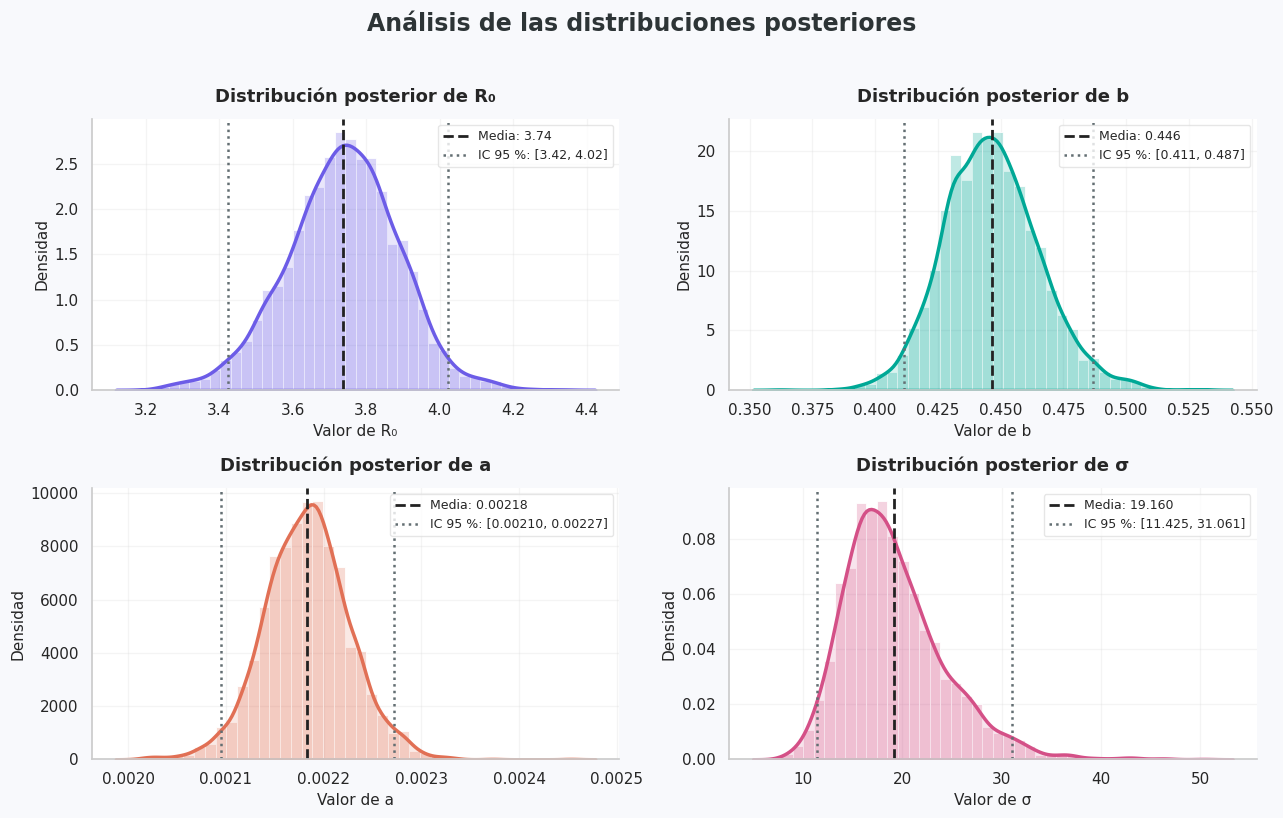

       RESUMEN DE LA CORRELACIÓN
Correlación posterior entre R₀ y b: -0.8860


In [39]:
# Configuración general del estilo de las gráficas
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11

# Extraemos las muestras posteriores de cada parámetro
post = idata.posterior

R0_s = post["R0"].values.flatten()
b_s = post["b"].values.flatten()
a_s = post["a"].values.flatten()
sigma_s = post["sigma"].values.flatten()

# Definimos los parámetros, sus colores y el formato numérico
parametros = [
    ("R₀", R0_s, "#6C5CE7", ".2f"),
    ("b", b_s, "#00A896", ".3f"),
    ("a", a_s, "#E17055", ".5f"),
    ("σ", sigma_s, "#D45087", ".3f")
]

# Creamos una figura de 2 filas y 2 columnas
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# Fondo general de la figura
fig.patch.set_facecolor("#F8F9FC")

# Graficamos la distribución posterior de cada parámetro
for ax, (nombre, v, color, fmt) in zip(axes.ravel(), parametros):

    # Calculamos la media y el intervalo de credibilidad del 95 %
    media = np.mean(v)
    lo, hi = np.percentile(v, [2.5, 97.5])

    # Dibujamos la distribución posterior suavizada
    sns.histplot(
        v,
        bins=40,
        stat="density",
        color=color,
        alpha=0.25,
        edgecolor="white",
        linewidth=0.6,
        ax=ax
    )

    sns.kdeplot(
        x=v,
        color=color,
        linewidth=2.5,
        fill=True,
        alpha=0.15,
        ax=ax
    )

    # Línea vertical para la media posterior
    ax.axvline(
        media,
        color="#222222",
        linestyle="--",
        linewidth=2,
        label=f"Media: {media:{fmt}}"
    )

    # Límites del intervalo de credibilidad del 95 %
    ax.axvline(
        lo,
        color="#636E72",
        linestyle=":",
        linewidth=1.8,
        label=f"IC 95 %: [{lo:{fmt}}, {hi:{fmt}}]"
    )

    ax.axvline(
        hi,
        color="#636E72",
        linestyle=":",
        linewidth=1.8
    )

    # Títulos y etiquetas
    ax.set_title(
        f"Distribución posterior de {nombre}",
        fontsize=13,
        pad=12
    )

    ax.set_xlabel(f"Valor de {nombre}")
    ax.set_ylabel("Densidad")

    # Mejoramos la apariencia de cada panel
    ax.legend(
        fontsize=9,
        frameon=True,
        facecolor="white",
        edgecolor="#E0E0E0",
        loc="best"
    )

    ax.grid(alpha=0.2)
    ax.set_facecolor("white")
    sns.despine(ax=ax)

# Título principal de la figura
fig.suptitle(
    "Análisis de las distribuciones posteriores",
    fontsize=17,
    fontweight="bold",
    color="#2D3436",
    y=1.02
)

# Ajustamos los espacios entre las gráficas
plt.tight_layout()
plt.show()


# CORRELACIÓN POSTERIOR ENTRE R₀ Y b

correlacion = np.corrcoef(R0_s, b_s)[0, 1]

print("=" * 50)
print("       RESUMEN DE LA CORRELACIÓN")
print("=" * 50)
print(f"Correlación posterior entre R₀ y b: {correlacion:.4f}")
print("=" * 50)


DINÁMICA EPIDEMIOLÓGICA ESTIMADA MEDIANTE PyMC
 Día  Susceptibles  Infectados  Recuperados
   0        762.00        1.00         0.00
   1        758.76        3.37         0.87
   2        748.04       11.18         3.78
   3        714.25       35.51        13.24
   4        622.47       99.16        41.37
   5        447.59      206.57       108.84
   6        258.50      283.36       221.13
   7        138.57      275.75       348.69
   8         80.18      222.23       460.59
   9         52.68      163.80       546.53
  10         38.92      115.64       608.44
  11         31.51       79.85       651.64
  12         27.26       54.46       681.28
  13         24.70       36.87       701.42
  14         23.11       24.85       715.03


/tmp/ipykernel_82815/2031856928.py:55: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


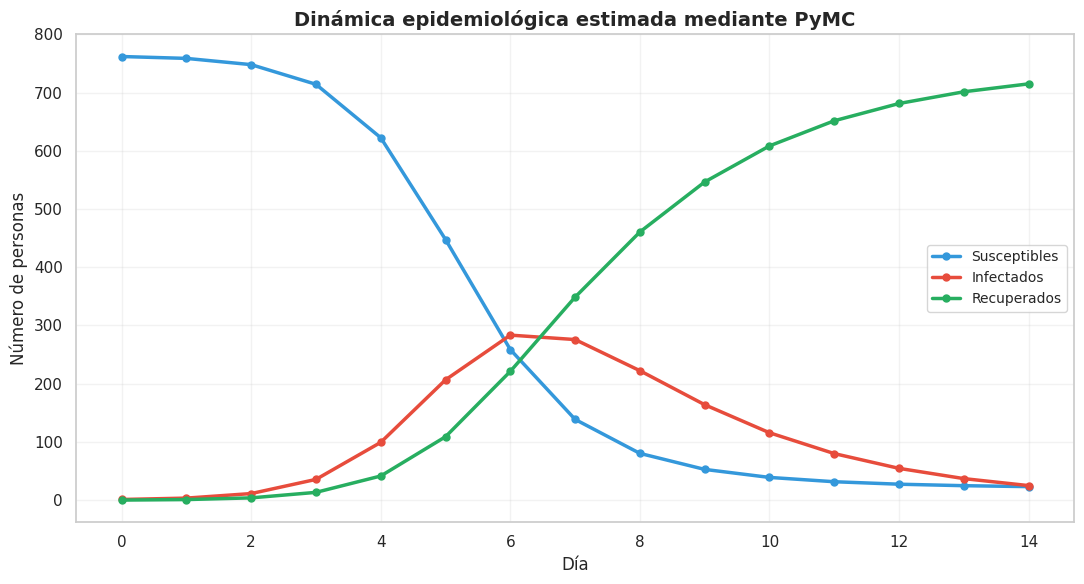

In [42]:
# ==========================================
# TABLA Y GRÁFICA DE LA DINÁMICA EPIDEMIOLÓGICA SIR
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# Creamos la tabla con los resultados del modelo
tabla_sir = pd.DataFrame({
    "Día": t_datos,
    "Susceptibles": S,
    "Infectados": I,
    "Recuperados": R
}).round(2)

# Imprimimos la tabla
print("\nDINÁMICA EPIDEMIOLÓGICA ESTIMADA MEDIANTE PyMC")
print(tabla_sir.to_string(index=False))

# Graficamos la evolución de los tres grupos
plt.figure(figsize=(11, 6))

plt.plot(
    t_datos, S,
    marker="o", markersize=5,
    linewidth=2.5, color="#3498DB",
    label="Susceptibles"
)

plt.plot(
    t_datos, I,
    marker="o", markersize=5,
    linewidth=2.5, color="#E74C3C",
    label="Infectados"
)

plt.plot(
    t_datos, R,
    marker="o", markersize=5,
    linewidth=2.5, color="#27AE60",
    label="Recuperados"
)

plt.xlabel("Día", fontsize=12)
plt.ylabel("Número de personas", fontsize=12)

plt.title(
    "Dinámica epidemiológica estimada mediante PyMC",
    fontsize=14,
    fontweight="bold"
)

plt.legend(frameon=True, fontsize=10)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

La tabla y la gráfica muestran la evolución estimada de las personas susceptibles, infectadas y recuperadas durante los 14 días analizados, utilizando los parámetros estimados mediante el enfoque bayesiano con PyMC.

Comparamos El óvalo de $x^2$
 y la posterior de PyMC

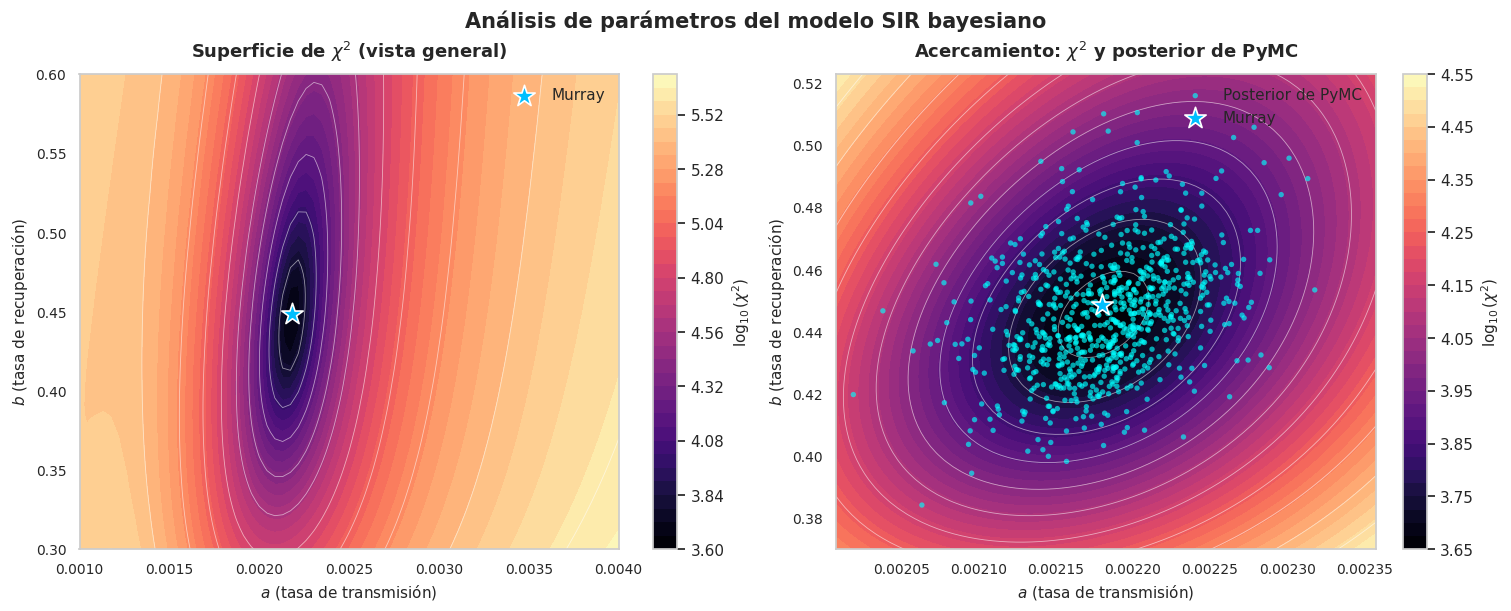

In [43]:

# Superficie de chi-cuadrada y posterior de PyMC

import numpy as np
import matplotlib.pyplot as plt


#  Calcular la superficie de chi-cuadrada


def chi2_malla(a, b):
    """Calcula chi-cuadrada para cada combinación de a y b."""

    sol = odeint(
        sir_ode_func,
        y0,
        np.r_[0, t_obs],
        args=((a, b),),
        rtol=1e-8
    )

    I_modelo = sol[1:, 1]
    return np.sum((I_obs - I_modelo)**2)


def malla_chi2(a_vals, b_vals):
    Z = np.zeros((len(b_vals), len(a_vals)))

    for i, ai in enumerate(a_vals):
        for j, bj in enumerate(b_vals):
            Z[j, i] = chi2_malla(ai, bj)

    return Z

#  Crear las mallas de parámetros


# Vista general
a_g = np.linspace(0.001, 0.004, 70)
b_g = np.linspace(0.3, 0.6, 70)

Z_general = malla_chi2(a_g, b_g)

# Evitamos logaritmos de cero
Z_general_log = np.log10(np.maximum(Z_general, 1e-12))


# Acercamiento a la región posterior
a_c, a_d = np.mean(a_s), np.std(a_s)
b_c, b_d = np.mean(b_s), np.std(b_s)

a_z = np.linspace(
    max(0.001, a_c - 4*a_d),
    min(0.004, a_c + 4*a_d),
    70
)

b_z = np.linspace(
    max(0.3, b_c - 4*b_d),
    min(0.6, b_c + 4*b_d),
    70
)

Z_zoom = malla_chi2(a_z, b_z)
Z_zoom_log = np.log10(np.maximum(Z_zoom, 1e-12))


# Configuración visual


fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    layout="constrained"
)

# Colores:
# magma = morado oscuro, rosa, naranja y amarillo
mapa_colores = "magma"


# Gráfica izquierda: vista general


cs1 = axes[0].contourf(
    a_g,
    b_g,
    Z_general_log,
    levels=35,
    cmap=mapa_colores
)

# Líneas de nivel
axes[0].contour(
    a_g,
    b_g,
    Z_general_log,
    levels=12,
    colors="white",
    linewidths=0.6,
    alpha=0.55
)

fig.colorbar(
    cs1,
    ax=axes[0],
    label=r'$\log_{10}(\chi^2)$',
    pad=0.02
)

# Parámetros de Murray
axes[0].scatter(
    a_murray,
    b_murray,
    color="deepskyblue",
    edgecolors="white",
    linewidths=1.2,
    marker="*",
    s=260,
    label="Murray",
    zorder=5
)

axes[0].set_title(
    r'Superficie de $\chi^2$ (vista general)',
    fontsize=13,
    fontweight="bold",
    pad=12
)

axes[0].set_xlabel(
    r'$a$ (tasa de transmisión)',
    fontsize=11
)

axes[0].set_ylabel(
    r'$b$ (tasa de recuperación)',
    fontsize=11
)

axes[0].legend(loc="upper right", framealpha=0.95)


# 5. Gráfica derecha: acercamiento a la posterior


cs2 = axes[1].contourf(
    a_z,
    b_z,
    Z_zoom_log,
    levels=35,
    cmap=mapa_colores
)

axes[1].contour(
    a_z,
    b_z,
    Z_zoom_log,
    levels=12,
    colors="white",
    linewidths=0.6,
    alpha=0.55
)

fig.colorbar(
    cs2,
    ax=axes[1],
    label=r'$\log_{10}(\chi^2)$',
    pad=0.02
)

# Muestras posteriores de PyMC
axes[1].scatter(
    a_s[::5],
    b_s[::5],
    s=15,
    color="cyan",
    edgecolors="none",
    alpha=0.65,
    label="Posterior de PyMC",
    zorder=4
)

# Parámetros de Murray
axes[1].scatter(
    a_murray,
    b_murray,
    color="deepskyblue",
    edgecolors="white",
    linewidths=1.2,
    marker="*",
    s=260,
    label="Murray",
    zorder=5
)

axes[1].set_title(
    r'Acercamiento: $\chi^2$ y posterior de PyMC',
    fontsize=13,
    fontweight="bold",
    pad=12
)

axes[1].set_xlabel(
    r'$a$ (tasa de transmisión)',
    fontsize=11
)

axes[1].set_ylabel(
    r'$b$ (tasa de recuperación)',
    fontsize=11
)

axes[1].set_xlim(a_z[0], a_z[-1])
axes[1].set_ylim(b_z[0], b_z[-1])

axes[1].legend(loc="upper right", framealpha=0.95)

#  Ajustes finales


for ax in axes:
    ax.tick_params(axis="both", labelsize=10)
    ax.grid(
        True,
        linestyle=":",
        linewidth=0.5,
        alpha=0.2
    )

fig.suptitle(
    r'Análisis de parámetros del modelo SIR bayesiano',
    fontsize=15,
    fontweight="bold")

plt.show()


**Interpretación de las graficas**

1. Panel Izquierdo: Superficie de $\chi^2$$\chi^2$ (Vista General)

* ¿Qué es la superficie de color? Representa la función de pérdida del error (en escala logarítmica de $\chi^2$$\chi^2$) en una malla amplia de valores para la tasa de transmisión ($a$$a$) y la tasa de recuperación ($b$$b$). Los colores más oscuros (tonos negros y morados en la paleta magma) indican las zonas de menor error, donde el modelo SIR se ajusta mejor a tus datos observados.
* La estrella azul (Murray): El punto azul con forma de estrella representa las estimaciones históricas que obtuvo Murray de manera clásica. Como se puede ver, cae exactamente en el fondo del foso o valle de menor error (la zona morada oscura), validando que dicho cálculo coincide con la región de mejor ajuste matemático global.
2. Panel Derecho: Acercamiento ($\chi^2$$\chi^2$ y posterior de PyMC)
* ¿Qué es el "óvalo"? Al hacer un acercamiento (zoom) drástico al valle de menor error, las curvas de nivel blancas revelan una forma elíptica o de óvalo inclinado. Esta orientación diagonal (de abajo-izquierda a arriba-derecha) tiene un significado epidemiológico real: existe una fuerte correlación positiva entre $a$$a$ y $b$$b$. Esto significa que si la tasa de transmisión $a$$a$ es ligeramente más alta, la tasa de recuperación $b$$b$ también debe serlo para lograr describir de manera similar la curva de infectados.
Los puntos cian (Posterior de PyMC): Representan las muestras que el algoritmo MCMC de PyMC generó para describir la incertidumbre de los parámetros.
* La coincidencia perfecta: Observa cómo la nube de puntos de PyMC se alinea de forma idéntica con la forma, inclinación y extensión del óvalo de $\chi^2$$\chi^2$. Esto demuestra visualmente que:
El método bayesiano ha encontrado con total precisión la zona óptima compatible con los mínimos cuadrados.
En lugar de darte un único punto fijo (como la estrella de Murray), PyMC te da toda la distribución de probabilidad (la nube cian), lo que te permite conocer con precisión el nivel de incertidumbre y la correlación real de tus estimaciones.


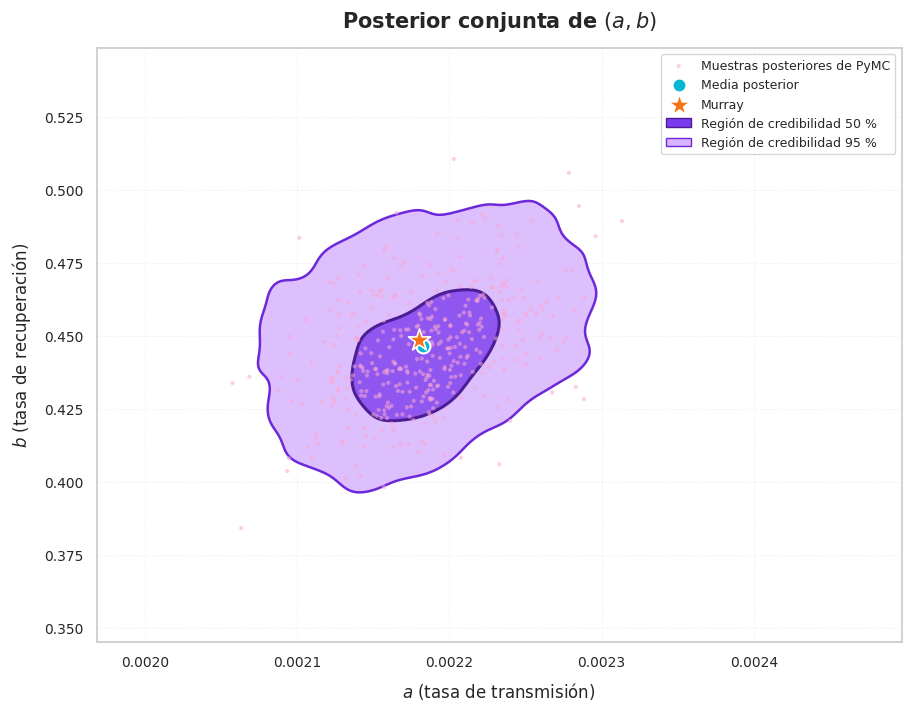

RESULTADOS DE LA POSTERIOR CONJUNTA
Media posterior de a: 0.002183
Media posterior de b: 0.446454
Correlación posterior entre a y b: 0.3258
¿Murray está dentro de la región de densidad del 95 %?: True


In [44]:

# Posterior conjunta de (a, b)

#  Estimar la densidad posterior conjunta


puntos = np.vstack([a_s, b_s])
kde = gaussian_kde(puntos)

dens = kde(puntos)

# Niveles de densidad para las regiones del 95 % y 50 %
nivel_95 = np.percentile(dens, 5)
nivel_50 = np.percentile(dens, 50)


# Construir la malla de evaluación


a_ext = np.linspace(
    a_s.min() - 0.1 * np.ptp(a_s),
    a_s.max() + 0.1 * np.ptp(a_s),
    250
)

b_ext = np.linspace(
    b_s.min() - 0.1 * np.ptp(b_s),
    b_s.max() + 0.1 * np.ptp(b_s),
    250
)

A_, B_ = np.meshgrid(a_ext, b_ext)

Zk = kde(
    np.vstack([A_.ravel(), B_.ravel()])
).reshape(A_.shape)

#  Crear la figura


fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")

# Nueva paleta de colores
color_95 = "#D8B4FE"  # Lila claro: región del 95 %
color_50 = "#7C3AED"  # Violeta intenso: región del 50 %
color_muestras = "#F9A8D4"  # Rosa: muestras posteriores
color_media = "#06B6D4"  # Turquesa: media posterior
color_murray = "#F97316"  # Naranja: punto de Murray

#  Regiones de credibilidad


ax.contourf(
    A_, B_, Zk,
    levels=[nivel_95, nivel_50, Zk.max()],
    colors=[color_95, color_50],
    alpha=0.85
)

# Contornos para delimitar las regiones
ax.contour(
    A_, B_, Zk,
    levels=[nivel_95, nivel_50],
    colors=["#6D28D9", "#4C1D95"],
    linewidths=[1.8, 2.2]
)

#  Muestras posteriores de PyMC


ax.scatter(
    a_s[::10],
    b_s[::10],
    s=9,
    color=color_muestras,
    alpha=0.55,
    edgecolors="none",
    label="Muestras posteriores de PyMC",
    zorder=3
)


# Media posterior


ax.scatter(
    a_s.mean(),
    b_s.mean(),
    color=color_media,
    edgecolors="white",
    linewidths=1.5,
    s=100,
    marker="o",
    label="Media posterior",
    zorder=5
)


#  Parámetros de Murray


ax.scatter(
    a_murray,
    b_murray,
    color=color_murray,
    marker="*",
    s=280,
    edgecolors="white",
    linewidths=1.2,
    label="Murray",
    zorder=6
)

# Etiquetas, título y leyenda


ax.set_xlim(a_ext[0], a_ext[-1])
ax.set_ylim(b_ext[0], b_ext[-1])

ax.set_xlabel(
    r"$a$ (tasa de transmisión)",
    fontsize=12,
    labelpad=8
)

ax.set_ylabel(
    r"$b$ (tasa de recuperación)",
    fontsize=12,
    labelpad=8
)

ax.set_title(
    r"Posterior conjunta de $(a,b)$",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Elementos adicionales de la leyenda
regiones = [
    Patch(
        facecolor=color_50,
        edgecolor="#4C1D95",
        label="Región de credibilidad 50 %"
    ),
    Patch(
        facecolor=color_95,
        edgecolor="#6D28D9",
        label="Región de credibilidad 95 %"
    )
]

handles, labels = ax.get_legend_handles_labels()

ax.legend(
    handles + regiones,
    labels + [r.get_label() for r in regiones],
    loc="best",
    fontsize=9,
    frameon=True,
    framealpha=0.95,
    edgecolor="#D1D5DB"
)

#  Estilo final

ax.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.25
)

ax.tick_params(axis="both", labelsize=10)

plt.show()


# Resultados numéricos


correlacion = np.corrcoef(a_s, b_s)[0, 1]

dens_murray = kde(
    np.array([[a_murray], [b_murray]])
)[0]

print("=" * 55)
print("RESULTADOS DE LA POSTERIOR CONJUNTA")
print("=" * 55)

print(f"Media posterior de a: {np.mean(a_s):.6f}")
print(f"Media posterior de b: {np.mean(b_s):.6f}")
print(f"Correlación posterior entre a y b: {correlacion:.4f}")

print(
    "¿Murray está dentro de la región de densidad del 95 %?:",
    bool(dens_murray >= nivel_95)
)


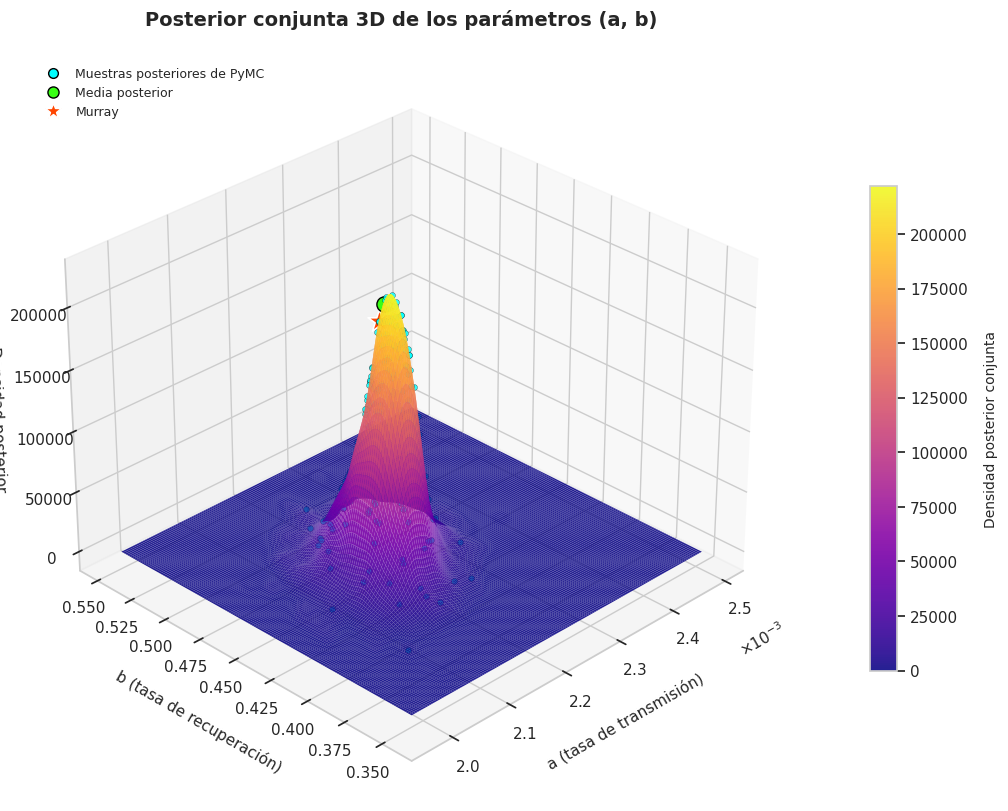

R0    = 3.74   IC 95 %: [3.42, 4.02]
I_max = 289 personas   IC 95 %: [266, 309]
Máximo observado en los datos: Max{axes=None}.0 personas

Método                     a           b        R0
Murray                  0.002180    0.4485    3.71
χ² + MH (propio)        0.002181    0.4452    3.74
PyMC (media posterior)  0.002183    0.4465    3.74
¿Murray está dentro del umbral de densidad del 95 %?: True


In [46]:

# - Posterior conjunta 3D de (a, b)


#  Estimar la densidad posterior conjunta


puntos = np.vstack([a_s, b_s])
kde = gaussian_kde(puntos)

#  Construir la malla tridimensional


a_ext = np.linspace(
    a_s.min() - 0.1 * np.ptp(a_s),
    a_s.max() + 0.1 * np.ptp(a_s),
    150
)

b_ext = np.linspace(
    b_s.min() - 0.1 * np.ptp(b_s),
    b_s.max() + 0.1 * np.ptp(b_s),
    150
)

A_, B_ = np.meshgrid(a_ext, b_ext)

# Evaluar la densidad posterior en cada punto de la malla
Zk = kde(
    np.vstack([A_.ravel(), B_.ravel()])
).reshape(A_.shape)


#Crear la figura 3D

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")


# Dibujar la superficie posterior


superficie = ax.plot_surface(
    A_,
    B_,
    Zk,
    cmap="plasma",
    edgecolor="none",
    antialiased=True,
    alpha=0.90,
    rcount=150,
    ccount=150
)

# Barra de color
cbar = fig.colorbar(
    superficie,
    ax=ax,
    shrink=0.65,
    pad=0.10,
    aspect=18
)

cbar.set_label(
    "Densidad posterior conjunta",
    fontsize=10,
    labelpad=12
)


#  Añadir muestras posteriores de PyMC


# Tomamos una de cada 20 muestras para evitar saturar la gráfica
indices = np.arange(0, len(a_s), 20)

dens_muestras = kde(
    np.vstack([a_s[indices], b_s[indices]])
)

ax.scatter(
    a_s[indices],
    b_s[indices],
    dens_muestras,
    color="#00FFFF",
    edgecolors="black",
    linewidths=0.25,
    s=18,
    alpha=0.8,
    depthshade=False
)


#  Marcar la media posterior


a_media = np.mean(a_s)
b_media = np.mean(b_s)

dens_media = kde(
    np.array([[a_media], [b_media]])
)[0]

ax.scatter(
    a_media,
    b_media,
    dens_media,
    color="#39FF14",
    edgecolors="black",
    linewidths=1,
    marker="o",
    s=120,
    depthshade=False
)


# Marcar los parámetros de Murray


dens_murray = kde(
    np.array([[a_murray], [b_murray]])
)[0]

ax.scatter(
    a_murray,
    b_murray,
    dens_murray,
    color="#FF4500",
    edgecolors="white",
    linewidths=1.2,
    marker="*",
    s=300,
    depthshade=False
)


#  Etiquetas y título


ax.set_xlabel(
    "a (tasa de transmisión)",
    fontsize=11,
    labelpad=12
)

ax.set_ylabel(
    "b (tasa de recuperación)",
    fontsize=11,
    labelpad=12
)

ax.set_zlabel(
    "Densidad posterior",
    fontsize=11,
    labelpad=10
)

ax.set_title(
    "Posterior conjunta 3D de los parámetros (a, b)",
    fontsize=14,
    fontweight="bold",
    pad=22
)


#  Leyenda personalizada


elementos = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor="#00FFFF",
        markeredgecolor="black",
        markersize=7,
        label="Muestras posteriores de PyMC"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor="#39FF14",
        markeredgecolor="black",
        markersize=8,
        label="Media posterior"
    ),
    Line2D(
        [0], [0],
        marker="*",
        color="w",
        markerfacecolor="#FF4500",
        markeredgecolor="white",
        markersize=12,
        label="Murray"
    )
]

ax.legend(
    handles=elementos,
    loc="upper left",
    fontsize=9,
    framealpha=0.9
)


#  Ajustes de visualización

ax.view_init(elev=30, azim=-135)

ax.ticklabel_format(
    axis="x",
    style="sci",
    scilimits=(0, 0),
    useMathText=True
)

ax.grid(True, alpha=0.25)

plt.show()

# Resultados numéricos

 #---- Máximo de infectados a partir de R0 ----
Imax_s = N * (1 - (1 + np.log(R0_s)) / R0_s)      # I_max = N·[1 - (1 + ln R0)/R0]
print(f"R0    = {R0_s.mean():.2f}   IC 95 %: [{np.percentile(R0_s, 2.5):.2f}, {np.percentile(R0_s, 97.5):.2f}]")
print(f"I_max = {Imax_s.mean():.0f} personas   IC 95 %: [{np.percentile(Imax_s, 2.5):.0f}, {np.percentile(Imax_s, 97.5):.0f}]")
print(f"Máximo observado en los datos: {I_datos.max()} personas")

# ---- Comparación con los otros métodos (valores de la práctica anterior) ----
print("\nMétodo                     a           b        R0")
print(f"Murray                  0.002180    0.4485    {0.00218 * N / 0.4485:.2f}")
print(f"χ² + MH (propio)        0.002181    0.4452    {0.002181 * N / 0.4452:.2f}")
print(f"PyMC (media posterior)  {a_s.mean():.6f}    {b_s.mean():.4f}    {R0_s.mean():.2f}")

print(
    "¿Murray está dentro del umbral de densidad del 95 %?:",
    bool(dens_murray >= np.percentile(kde(puntos), 5))
)


En este código podemos ver cómo se distribuyen los parámetros $(a )$ y $(b )$, comparar los resultados que obtuvimos con los valores de Murray y calcular el número reproductivo $(R_0 )$ y el máximo de personas infectadas que predice el modelo.
- Gráfica 3D: nos muestra qué combinaciones de $(a )$ y $(b)$ son más probables. También podemos ver las muestras de PyMC, la media de los parámetros y los valores de Murray.
- Resultados numéricos: nos permiten estimar el número reproductivo y el máximo de infectados, junto con sus intervalos de incertidumbre del 95 %, para compararlos con los datos observados.
- Comparación de métodos: podemos revisar qué tan diferentes son los resultados obtenidos con Murray, el método $(\chi^2+\text{MH} )$ y PyMC.
- Densidad posterior: nos ayuda a observar si los valores de Murray se encuentran en una zona de densidad alta, aunque esto no garantiza que estén dentro de una región creíble conjunta del 95 %.
En general, con este análisis podemos comparar los métodos y entender mejor la incertidumbre de los parámetros y las predicciones del modelo SIR.

## <span style="color:orange;">**Conclusión**</span>


El modelo SIR bayesiano en PyMC permitió estimar los parámetros $(R_0\approx 3.7 )$, $(b\approx 0.45 )$ y $(a\approx 0.0022 )$. La convergencia se evaluó mediante \(\hat R\), ESS, divergencias y trazas. El pico estimado de infectados $(289)$ fue cercano al observado $(294)$. Además, el enfoque bayesiano permite cuantificar la incertidumbre de las estimaciones.
Mientras que en limitaciones, el modelo presenta diferencias en los últimos días del brote. Además, la verosimilitud normal puede generar predicciones negativas y las distribuciones previas pueden influir en los resultados. Se podrían explorar otros modelos de error y métodos numéricos más eficientes.